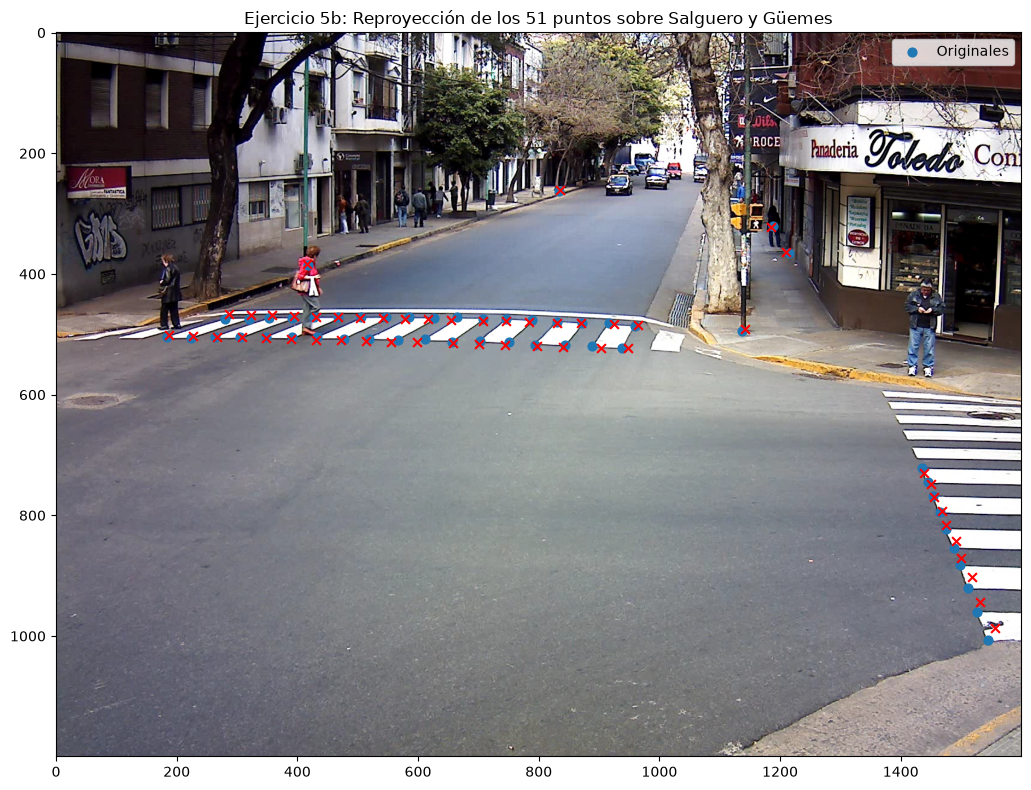

In [2]:
import alc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

Para generar el txt con los puntos extraidos de las imagenes del item 3

In [ ]:
import cv2
import numpy as np

puntos_totales = []

# Iterar sobre las 20 imágenes del tablero
for i in range(1, 21):
    ruta = f' calib/coplanar/Im_R_{i}.png'
    img = cv2.imread(ruta)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    encontrado, esquinas = cv2.findChessboardCorners(gray, (11, 7), None)

    if encontrado:
        puntos_totales.append(esquinas.reshape(-1, 2))

# una sola matriz de 1540 filas (20 imágenes * 77 puntos) x 2 columnas
matriz_puntos = np.vstack(puntos_totales)

np.savetxt('mis_puntos_extraidos.txt', matriz_puntos, delimiter=',')

**Ejercicio 2 - Calibración con puntos 3D**

a)

In [ ]:
todosLosPuntos2D = np.loadtxt(' calib/3d/detected_corners.txt')
puntos3D = np.loadtxt(' calib/3d/p_W_corners.txt', delimiter=',')

# Extraemos solo la primera fila (correspondiente a img_0001.jpg)
# y la redimensionamos a una matriz de 12 filas x 2 columnas (u, v)
puntos2D = todosLosPuntos2D[0].reshape(12, 2)

Q = alc.obtenerQ3d(puntos2D, puntos3D)

M = alc.resolverDLT3D(Q)

R, t, K = alc.devolverMatricesCalibracion3d(M)

# Mostrar resultados
print("Matriz de Proyección M:\n", M)
print("\nMatriz de Rotación R:\n", R)
print("\nVector de Traslación t:\n", t)
print("\nMatriz de Parámetros Intrínsecos K:\n", K)

Matriz de Proyección M:
 [[-6.44865266e-02 -2.27816085e-02  1.39906512e-02 -8.37825121e-01]
 [-3.69903840e-03 -6.10180404e-02 -1.31187333e-02 -5.37810986e-01]
 [-8.83537006e-05 -4.47215928e-05 -7.79036987e-05 -5.11440314e-03]]

Matriz de Rotación R:
 [[-0.618213   -0.12921397  0.77531699]
 [ 0.35508353 -0.92591643  0.12881947]
 [-0.70123346 -0.35494017 -0.61829533]]

Vector de Traslación t:
 [[ 18.16793831]
 [ 14.50326886]
 [-40.59128918]]

Matriz de Parámetros Intrínsecos K:
 [[ 4.25859862e+02 -1.56351856e-02  3.54418499e+02]
 [ 0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


b)

In [ ]:
_,_, K_rest = alc.devolverMatricesCalibracion3d(M,restriccion=True)
print("\nMatriz de Parámetros Intrínsecos K con αu = αv y K12 = 0.:\n", K_rest)


Matriz de Parámetros Intrínsecos K con αu = αv y K12 = 0.:
 [[425.21258467   0.         354.41849869]
 [  0.         425.21258467 256.85335534]
 [  0.           0.           1.        ]]


**Ejercicio 3 - Calibración con puntos coplanares**

a) Por Teorema de la Dimensión: $Rg(Q) + dim(Nu(Q)) = 9$. Para que el sistema homogéneo $Q*h = 0$ tenga una solución no nula única salvo por un factor de escala, el núcleo de $Q$ debe tener dimensión 1. Por lo tanto, $Rg(Q) = 9 - 1 = 8$. La matriz $Q$ debe tener rango 8. Lo cual requiere que mínimo $n = 4$


In [ ]:
#Puntos en las imagenes
todos_los_puntos_2d = np.loadtxt('mis_puntos_extraidos.txt', delimiter=',')
imgPts_todas = todos_los_puntos_2d.reshape(20, 77, 2)

#Puntos del tablero
objPts = np.zeros((77, 3))
k = 0
for j in range(7):
    for i in range(11):
        objPts[k, 0] = 30 * i
        objPts[k, 1] = 30 * j
        k += 1

Hlst = []

# Para cada una de las 20 vistas
for j in range(20):

    imgPts_actual = imgPts_todas[j]
    H_actual = alc.resolverHomografia(objPts, imgPts_actual)
    Hlst.append(H_actual)


# Imprimimos la primera homografía calculada (H_1)
print("Matriz de Homografía H (primera imagen):")
print(np.round(Hlst[0], 4))

A=alc.armarA(Hlst)
print("\nDimension de A:")
print(A.shape)

K=alc.calcularMatrizK2D(A)
print("\nMatriz K:")
print(K)

r1,t1=alc.obtenerPose2D(K,Hlst[0])
print("\nDe la primera imagen:")
print("R1:\n",np.round(r1,4))
print("t1:\n",np.round(t1,4))

Matriz de Homografía H (primera imagen):
[[ 1.379600e+00 -2.660000e-02  3.726671e+02]
 [ 3.160000e-02  1.369300e+00  1.042765e+02]
 [ 1.000000e-04 -0.000000e+00  1.000000e+00]]

Dimension de A:
(40, 6)

Matriz K:
[[743.33332466  -0.91231188 519.76608306]
 [  0.         754.50705995 298.47729979]
 [  0.           0.           1.        ]]

De la primera imagen:
R1:
 [[ 9.999e-01 -1.440e-02 -1.000e-04]
 [ 1.440e-02  9.999e-01  0.000e+00]
 [ 1.000e-04 -0.000e+00  1.000e+00]]
t1:
 [[0.2019]
 [0.2555]
 [0.0018]]


**Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad** \
a)

In [3]:
# Habria que aclarar que si bien el enunciado pide considerar que Z=0,1 para algunos
# puntos, necesitamos despreciarlo ya que no tenemos los puntos necesarios (6) para
# utilizar DLT en 3 dimensiones??

df = pd.read_csv('salguero/world_img_pts.csv', sep=';')
datos = np.asarray(df)

objPts_a = datos[:, 1:3] #Coordenadas (X, Y) de los 5 puntos, Matirz de (5,2)

H_lista= []

#Usamos Método de Zhang (Ejercicio 3 del TP) para obtener la matriz K

for i in range(4): #Tenemos 4 puntos de vista, armamos una matriz HK para cada uno
    u = 4 + 2 * i
    v = 4 + 2 * i + 1
    imgPts_a = datos[:, u:v+1] # (uk, vk) coordenadas de los 5 puntos en la imagen k

    Q2d = alc.obtenerQ2d(imgPts_a, objPts_a)

    _,_,V = alc.svd_reducida(Q2d, k=9, tol=-1)
    h = V[:,-1] # el vector singular asociado al menor valor singular
    Hk = h.reshape((3,3))

    H_lista.append(Hk)

A_Zhang = alc.armarA(H_lista)
K = alc.calcularMatrizK2D(A_Zhang)

print("Matriz de Parámetros Intrínsecos K:")
print(K)

Matriz de Parámetros Intrínsecos K:
[[2.78278008e+03 1.35536578e+03 2.89090322e+02]
 [0.00000000e+00 2.13055733e+02 1.95627005e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


b)

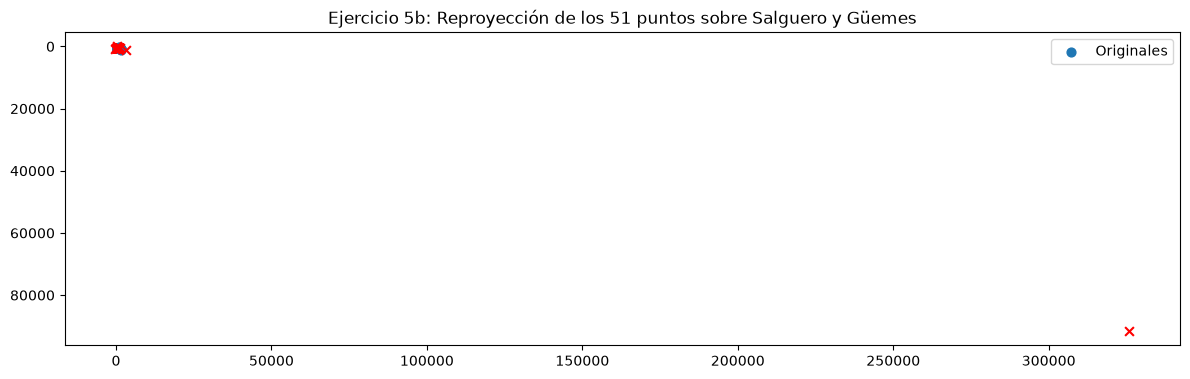

In [4]:
datos_b = np.loadtxt('salguero/gs_10_09_point_correspondences_v5.txt')

objPts_b = alc.traspuesta(datos_b[1:4, :])
imgPts_b = alc.traspuesta(datos_b[4:6, :])

mask_calle = (objPts_b[:, 2] == 0.0)
objPts_calle = objPts_b[mask_calle, 0:2]  #solo (X, Y) de los puntos con Z = 0
imgPts_calle = imgPts_b[mask_calle, :]

# Esta función va en alc.py
# Normalización isotrópica de Hartley, para no perder precisión por svd_reducida
def normalizar2D(pts):
    c = np.mean(pts, axis=0)
    d = np.mean(np.sqrt((pts[:, 0] - c[0])**2 + (pts[:, 1] - c[1])**2))
    s = np.sqrt(2.0) / d
    T = np.array([[s, 0.0, -s * c[0]],
                [0.0, s, -s * c[1]],
                [0.0, 0.0, 1.0]])
    pts_n = (pts - c) * s
    return pts_n, T

obj_norm, T_mundo = normalizar2D(objPts_calle)
img_norm, T_img = normalizar2D(imgPts_calle)

Q_b = alc.obtenerQ2d(img_norm, obj_norm)

_,_, V_b = alc.svd_reducida(Q_b, k=9, tol=-1)
h_b_norm = V_b[:, -1]
H_b_norm = h_b_norm.reshape((3, 3))

# Desnormalizamos H_b = T_img^(-1) * H_norm * T_mundo
H_b = alc.prodMat(alc.prodMat(alc.inversa(T_img), H_b_norm), T_mundo)
H_b = H_b / H_b[2, 2]

R_b, t_b = alc.obtenerPose2D(H_b, K)

# Tomamos los 51 puntos en 3D (X, Y, Z) como matriz de (3, 51)
# Esto incluye tanto los de la calle (Z = 0) como los del cordón (Z = 0.1)
pts3D_todos = datos_b[1:4, :] 

t_b_col = t_b.reshape((3, 1))

# Ecuación (1) Pasamos del mundo real a coordenadas de la cámara
pts_camara = alc.prodMat(R_b, pts3D_todos) + t_b_col

# Ecuación (2) Pasamos de coordenadas de la cámara al plano imagen con K
Proy_pinhole = alc.prodMat(K, pts_camara)

# Dividimos por la tercera coordenada (lambda) para obtener los píxeles (u, v)
u_ReProy = Proy_pinhole[0, :] / Proy_pinhole[2, :]
v_ReProy = Proy_pinhole[1, :] / Proy_pinhole[2, :]


#Graficamos
img = plt.imread('salguero/img_10_18_47_351.jpg')
plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.scatter(imgPts_b[:, 0], imgPts_b[:, 1], s=40, label='Originales')
plt.scatter(u_ReProy, v_ReProy, marker='x', color='red', s=40)
plt.legend()
plt.title('Ejercicio 5b: Reproyección de los 51 puntos sobre Salguero y Güemes')
plt.tight_layout()
plt.show()

c) está feo pero da bien(?

In [43]:
señora=np.loadtxt('señora.txt')
tiemposSeñora=señora[:,0] #timestamp en segundos
ptsSeñora=np.ones((6,3))
ptsSeñora[:,0:2]=señora[:,1:3] #puntos en el tablero

H_inv=alc.inversa(H_b)

#Aplica H-1 a cada punto en la imagen para pasarlo a coords reales
for i in range(6):
  ptsSeñora[i,:]=alc.calcularAx(H_inv,ptsSeñora[i,:])
  ptsSeñora[i,:]=ptsSeñora[i,:]/ptsSeñora[i,2]

coords_xy = ptsSeñora[:, 0:2]
# Calculamos las diferencias (dX, dY) entre puntos consecutivos
# np.diff resta la fila i a la fila i+1 para todo el array
diferencias = np.diff(coords_xy, axis=0)
# Calculamos la distancia euclidiana de cada tramo parcial
distancias_parciales = np.sqrt(np.sum(diferencias**2, axis=1))
# Calculamos la distancia total sumando todos los tramos
distancia_total = np.sum(distancias_parciales)
# Calculamos el tiempo total
tiempo_total = tiemposSeñora[5] - tiemposSeñora[0]
# Calculamos la velocidad final
velocidad_m_s = distancia_total / tiempo_total
velocidad_km_h = velocidad_m_s * 3.6

print(f"\nSeñora:\nDistancia total recorrida: {distancia_total:.2f} m")
print(f"Tiempo total: {tiempo_total:.3f} s")
print(f"Velocidad: {velocidad_m_s:.2f} m/s ({velocidad_km_h:.2f} km/h)")

taxi=np.loadtxt('taxi.txt')
tiemposTaxi=taxi[:,0] #timestamp en segundos
ptsTaxi=np.ones((6,3))
ptsTaxi[:,0:2]=taxi[:,1:3] #puntos en el tablero

for i in range(6):
  ptsTaxi[i,:]=alc.calcularAx(H_inv,ptsTaxi[i,:])
  ptsTaxi[i,:]=ptsTaxi[i,:]/ptsTaxi[i,2]

coords_xy2 = ptsTaxi[:, 0:2]
diferencias2 = np.diff(coords_xy2, axis=0)
distancias_parciales2 = np.sqrt(np.sum(diferencias2**2, axis=1))
distancia_total2 = np.sum(distancias_parciales2)
tiempo_total2 = tiemposTaxi[5] - tiemposTaxi[0]
velocidad_m_s2 = distancia_total2 / tiempo_total2
velocidad_km_h2 = velocidad_m_s2 * 3.6

print(f"\nTaxi:\nDistancia total recorrida: {distancia_total2:.2f} m")
print(f"Tiempo total: {tiempo_total2:.3f} s")
print(f"Velocidad: {velocidad_m_s2:.2f} m/s ({velocidad_km_h2:.2f} km/h)")

camioneta=np.loadtxt('camioneta.txt')
tiemposCamioneta=camioneta[:,0] #timestamp en segundos
ptsCamioneta=np.ones((6,3))
ptsCamioneta[:,0:2]=camioneta[:,1:3] #puntos en el tablero

for i in range(6):
  ptsCamioneta[i,:]=alc.calcularAx(H_inv,ptsCamioneta[i,:])
  ptsCamioneta[i,:]=ptsCamioneta[i,:]/ptsCamioneta[i,2]

coords_xy3 = ptsCamioneta[:, 0:2]
diferencias3 = np.diff(coords_xy3, axis=0)
distancias_parciales3 = np.sqrt(np.sum(diferencias3**2, axis=1))
distancia_total3 = np.sum(distancias_parciales3)
tiempo_total3 = tiemposCamioneta[5] - tiemposCamioneta[0]
velocidad_m_s3 = distancia_total3 / tiempo_total3
velocidad_km_h3 = velocidad_m_s3 * 3.6

print(f"\nCamioneta:\nDistancia total recorrida: {distancia_total3:.2f} m")
print(f"Tiempo total: {tiempo_total3:.3f} s")
print(f"Velocidad: {velocidad_m_s3:.2f} m/s ({velocidad_km_h3:.2f} km/h)")


Señora:
Distancia total recorrida: 7.06 m
Tiempo total: 4.992 s
Velocidad: 1.41 m/s (5.09 km/h)

Taxi:
Distancia total recorrida: 67.39 m
Tiempo total: 4.992 s
Velocidad: 13.50 m/s (48.59 km/h)

Camioneta:
Distancia total recorrida: 72.55 m
Tiempo total: 4.992 s
Velocidad: 14.53 m/s (52.32 km/h)
